# Human myoblast differentiation: GSE52529

This notebook adds the human skeletal muscle myoblast time course used in the original Monocle pseudotime study. It plots the observed 0, 24, 48, and 72 hour collection times and estimates diffusion pseudotime (DPT) from an early collection-time root. DPT is inferred from expression neighborhoods; it is not the observed collection time. GEO sample flags are used to exclude debris, control wells, and wells with anything other than one cell.

Source: Trapnell et al., [The dynamics and regulators of cell fate decisions are revealed by pseudotemporal ordering of single cells](https://doi.org/10.1038/nbt.2859); [GEO GSE52529](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE52529).

In [17]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
import numpy as np
import pandas as pd
import scanpy as sc
from scipy.spatial.distance import cdist
from matplotlib.collections import LineCollection
%config InlineBackend.figure_format = 'retina'

NOTEBOOK_DIR = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd() / "notebooks"
sys.path.insert(0, str(NOTEBOOK_DIR / "src"))
from biological_comparison import load_gse52529_myoblasts, make_imste, make_umap

RANDOM_STATE = 42
N_HVG = 1000
N_PCS = 50

## Load the processed single-cell matrix

The GEO matrix contains FPKM values (not raw counts). The loader keeps 306 clean single-cell profiles from 372 matrix columns, then applies `log1p`, highly variable gene selection, scaling, and PCA.


In [18]:
myoblast = load_gse52529_myoblasts(random_state=RANDOM_STATE, n_hvg=N_HVG, n_pcs=N_PCS)
time_summary = (pd.DataFrame({"time_hours": myoblast["time_hours"]})
                .value_counts("time_hours").sort_index().rename("cells").reset_index())
display(time_summary)
X = myoblast["X"]
time_hours = myoblast["time_hours"]


/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/scanpy/preprocessing/_highly_variable_genes.py:336: RuntimeWarning: invalid value encountered in log
  dispersion = np.log(dispersion)


,time_hours,cells
0,0,81
1,24,76
2,48,85
3,72,64


## Compare IMSTE and UMAP by collection time

Both methods receive the same PCA coordinates. The observed time labels are only used to color the resulting plots.


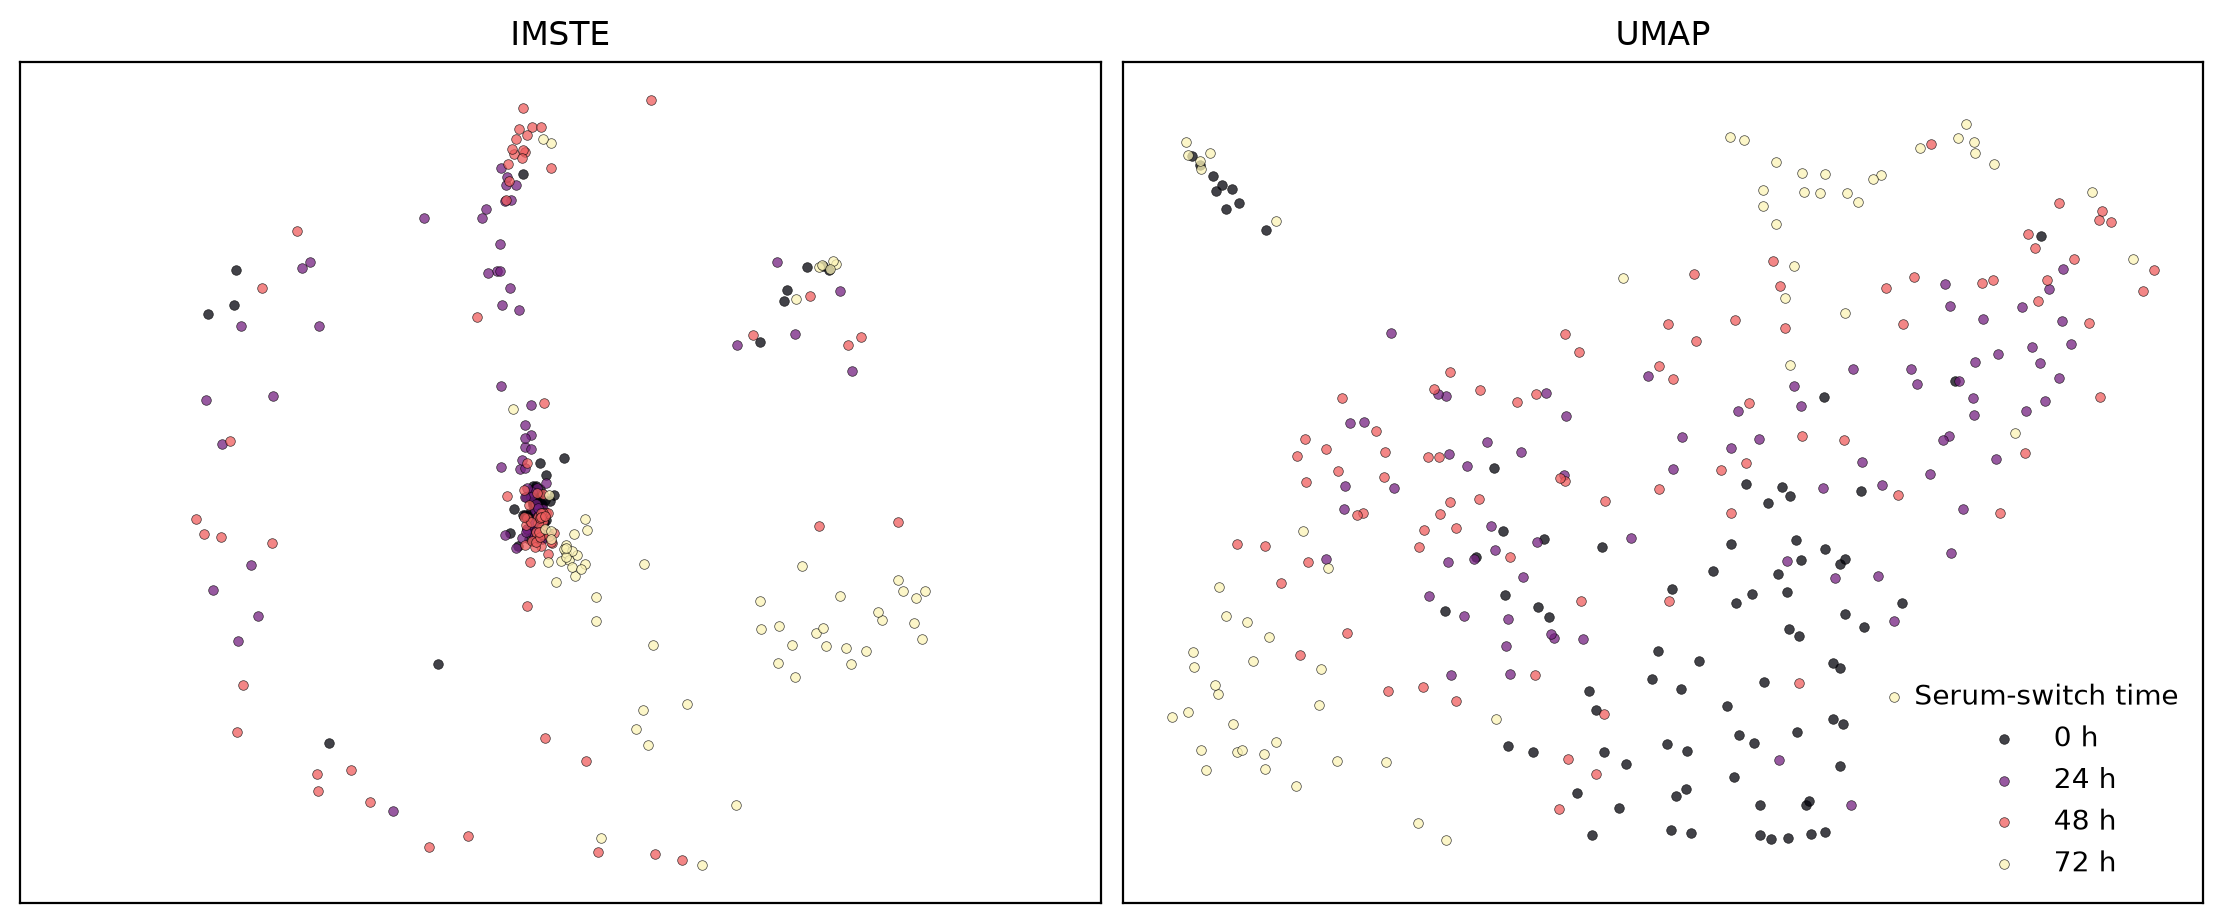

In [19]:
imste = make_imste(n_components=2, n_msts=105, n_epochs=2000, random_state=RANDOM_STATE)
umap = make_umap(n_components=2, n_neighbors=20, min_dist=0.1, random_state=RANDOM_STATE)
Z_imste = imste.fit_transform(X)
Z_umap = umap.fit_transform(X)

time_order = sorted(np.unique(time_hours))
colors = plt.get_cmap("magma")(np.linspace(0.02, 0.98, len(time_order)))
color_by_time = {hour: colors[i] for i, hour in enumerate(time_order)}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
for ax, Z, title in zip(axes, (Z_imste, Z_umap), ("IMSTE", "UMAP")):
    for hour in time_order:
        mask = time_hours == hour
        ax.scatter(Z[mask, 0], Z[mask, 1], s=12, alpha=0.75,
                   edgecolors="black", linewidths=0.25,
                   color=color_by_time[hour], label=f"{hour} h")
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_aspect("equal", adjustable="datalim")
axes[1].legend(title="Serum-switch time", frameon=False)
plt.show()

## Estimate diffusion pseudotime

Use the cell nearest the 0 hour PCA centroid as the root, then calculate DPT on a nearest-neighbor graph of the same PCA features. Collection time provides an external reference for interpreting the inferred ordering. Thin lines connect each cell to its nearest higher-DPT cell in the displayed 2D embedding; they are local direction cues, not inferred lineage edges. A single DPT axis can simplify a branching process, so inspect the scatter and per-timepoint distributions rather than treating it as ground truth.


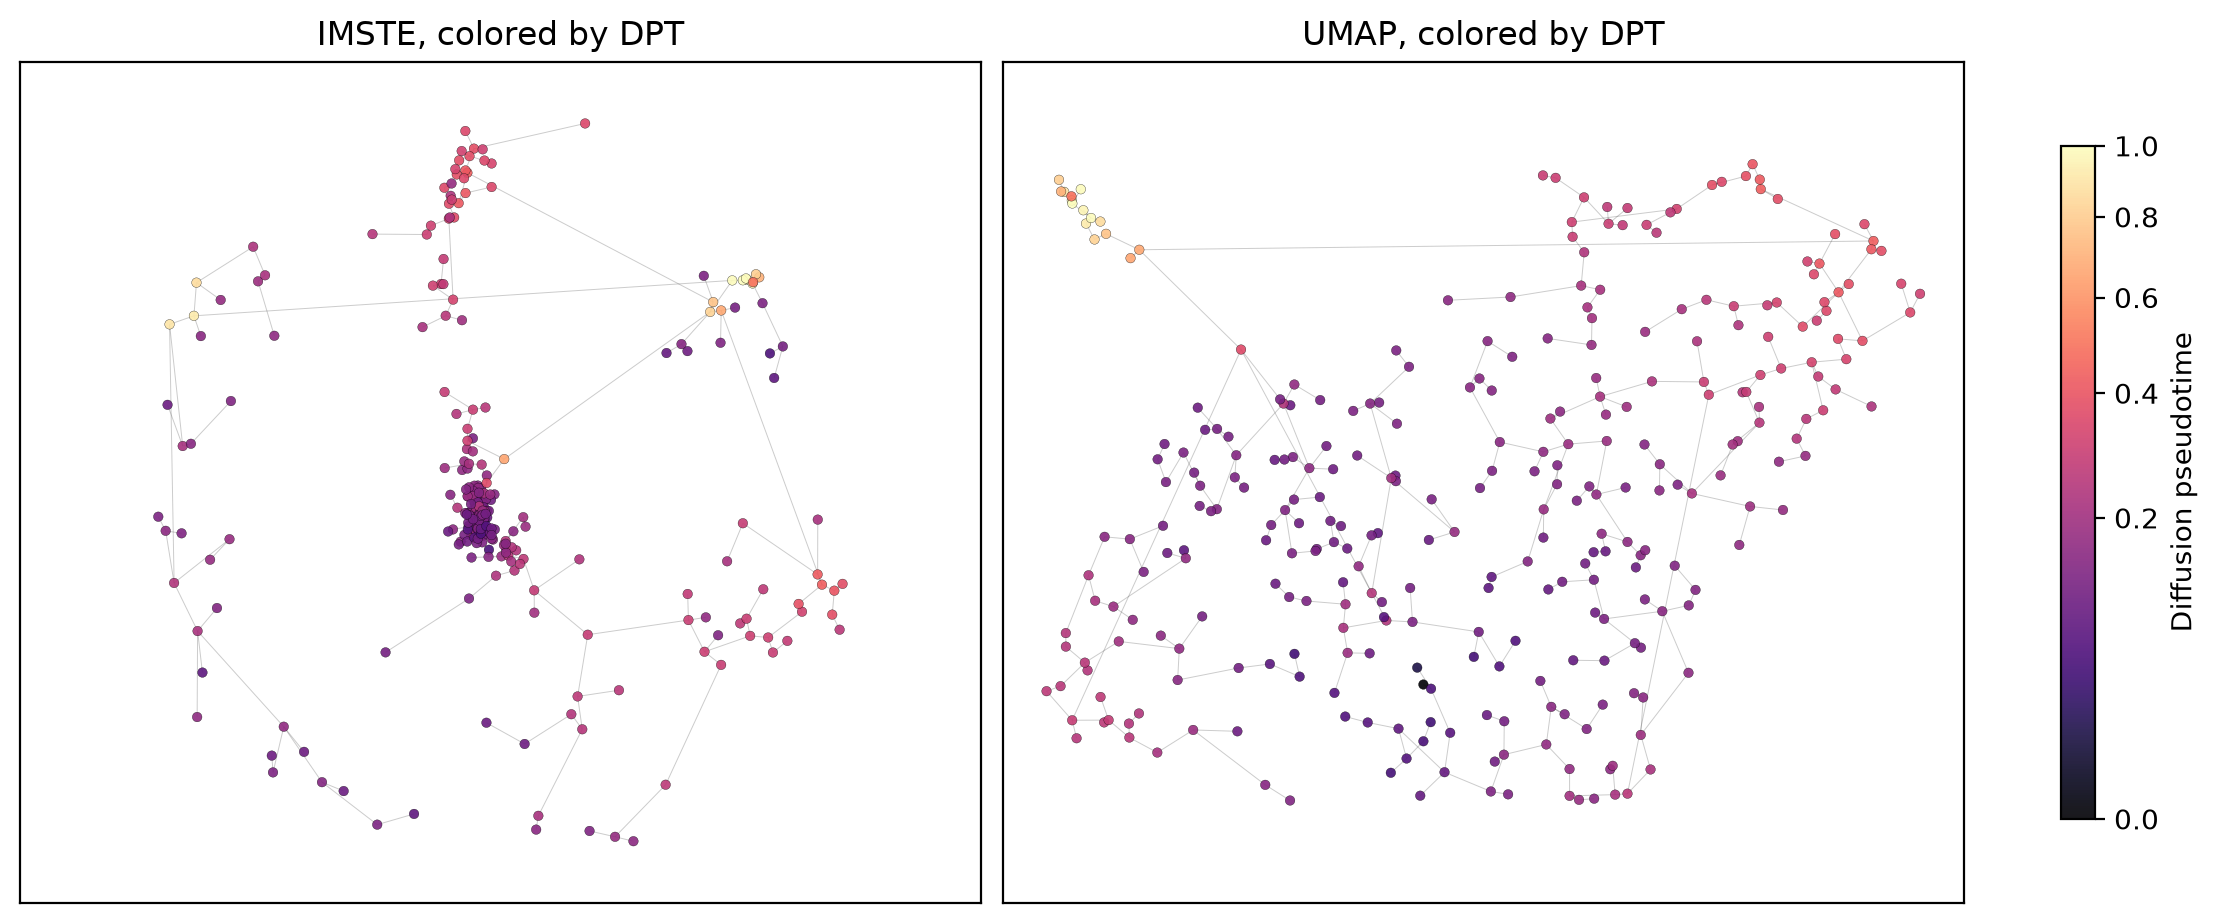

,count,median,min,max
time_hours,,,,
0,81,0.129588,0.000000,0.984654
24,76,0.164834,0.045088,0.412005
48,85,0.137302,0.050094,0.435152
72,64,0.259202,0.068155,1.000000


In [20]:
trajectory = sc.AnnData(X=X.copy())
trajectory.obs["time_hours"] = time_hours
early = np.flatnonzero(time_hours == min(time_order))
early_center = X[early].mean(axis=0)
root_index = early[np.argmin(np.sum((X[early] - early_center) ** 2, axis=1))]
trajectory.uns["iroot"] = int(root_index)
sc.pp.neighbors(trajectory, n_neighbors=15, use_rep="X", random_state=RANDOM_STATE)
sc.tl.diffmap(trajectory)
sc.tl.dpt(trajectory, n_dcs=10)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
dpt_values = trajectory.obs["dpt_pseudotime"].to_numpy()
dpt_norm = PowerNorm(gamma=0.5, vmin=0, vmax=1)
def nearest_higher_dpt_segments(Z, values):
    distances = cdist(Z, Z)
    higher = values[None, :] > values[:, None]
    distances[~higher] = np.inf
    nearest = distances.argmin(axis=1)
    rows = np.arange(len(Z))
    valid = np.isfinite(distances[rows, nearest])
    return np.stack((Z[valid], Z[nearest[valid]]), axis=1)
for ax, Z, title in zip(axes, (Z_imste, Z_umap), ("IMSTE", "UMAP")):
    segments = nearest_higher_dpt_segments(Z, dpt_values)
    ax.add_collection(LineCollection(segments, colors="#333333",
                                     linewidths=0.35, alpha=0.25, zorder=1))
    points = ax.scatter(Z[:, 0], Z[:, 1], c=dpt_values, cmap="magma", norm=dpt_norm,
                        s=12, alpha=0.9, edgecolors="black", linewidths=0.12, zorder=2)
    ax.set_title(f"{title}, colored by DPT")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_aspect("equal", adjustable="datalim")
fig.colorbar(points, ax=axes, label="Diffusion pseudotime", shrink=0.8)
plt.show()

dpt_by_time = (pd.DataFrame({"time_hours": time_hours,
                             "dpt": trajectory.obs["dpt_pseudotime"].to_numpy()})
              .groupby("time_hours")["dpt"]
              .agg(["count", "median", "min", "max"]))
display(dpt_by_time)

## Data notes

This is a processed FPKM matrix rather than raw UMI counts. Cell profiles were collected at four timepoints after serum switch. The original study used Monocle to recover a differentiation progression and also identified a non-differentiating contaminant branch. The DPT result here is a fresh analysis on this project’s PCA neighborhood graph, not a reproduction of the original Monocle trajectory. See [`data/gse52529/README.md`](../data/gse52529/README.md) for provenance and filtering details.